In [15]:

import json
import requests
import calendar
import geopandas as gpd
import pandas as pd
import numpy as np
import xarray as xr
import rioxarray

from datetime import date
from matplotlib import pyplot as plt
from pystac_client import Client
from odc.stac import load
from shapely.geometry import Polygon, LineString
from rasterio.features import rasterize

In [11]:
def bboxToSWNEString(bbox):
    return f"{bbox[1]}, {bbox[0]}, {bbox[3]}, {bbox[2]}"

BBOX = [-58.12,-51.43,-58.04,-51.39] # W S E N Format
SENTINEL_CLIENT_URL = "https://earth-search.aws.element84.com/v1"
OVERPASS_API_URL = "https://overpass.openstreetmap.fr/api/interpreter" # French endpoint works better for some reason
SENTINEL_BANDS = ["red", "green", "blue", "nir", "scl"]
OVERPASS_HEADERS = {
    'User-Agent': 'WaterSegmenter/1.0 (zyoxthecoder@gmail.com)'
}

In [18]:
# Sentinel Data

def fetchSentinelData(clientURL: str = SENTINEL_CLIENT_URL, bbox: list=BBOX, onlyUseMonths: list = [12, 1, 2, 3], bands=SENTINEL_BANDS, cloudPercent: int = 5):
    TAG = "[SENTINEL]"
    print(f"{TAG} Connecting to {clientURL}")
    client = Client.open(SENTINEL_CLIENT_URL)
    print(f"{TAG} Connected!")

    year = 2025

    while True:
        for month in onlyUseMonths:
            lastDay = calendar.monthrange(year, month)[1]
            startDate = date(year, month, 1)
            endDate = date(year, month, lastDay)
            dateString = f"{startDate}/{endDate}"

            print(f"{TAG} Trying to fetch data for", dateString)
            search = client.search(
                collections=["sentinel-2-l2a"],
                bbox=bbox,
                datetime=dateString,
                query={"eo:cloud_cover": {"lt": cloudPercent}}
            )

            if (search.matched() == 0):
                print(f"{TAG} No data found, trying next month")
                continue
            else:
                break
        if (search.matched() != 0):
            break

        year -= 1

        if (year < 2015): 
            return None

    print(f"{TAG} Found {search.matched()} matching satellite scenes.")
    print(f"{TAG} Fetching data...")

    data = load(
        search.items(),
        bands=bands,
        bbox=bbox,
        resolution=10,
        chunks={}
    )

    print(f"{TAG} Fetched sentinel data successfully!")
    return data

In [36]:
def fetchOverpassData(url=OVERPASS_API_URL, headers=OVERPASS_HEADERS, query=""):
    TAG = "[OVERPASS]"
    if (query == ""):
        raise ValueError("Please provide a valid Overpass query")

    print(f"{TAG} Fetching query results from {url}...")
    response = requests.get(url, params={'data': query}, headers=headers)

    if response.status_code == 200:
        overpassData = response.json()
        print(f"{TAG} Successfully fetched {len(overpassData.get('elements', []))} water elements!")
        return overpassData
    elif response.status_code == 400:
        print(f"{TAG} Error 400, probably invalid query: {response.text}")
        return None
    else: 
        print(f"{TAG} Error {response.status_code}: {response.text}")
        return None

def prepareOverpassData(overpassData, target_crs):
    features = []
    for element in overpassData.get('elements', []):
        if element.get('type') == 'way' and 'geometry' in element:
            coords = [(pt['lon'], pt['lat']) for pt in element['geometry']]
            if len(coords) >= 3:
                poly = Polygon(coords)
                features.append({'geometry': poly, 'id': element.get('id')})

    return gpd.GeoDataFrame(features, crs="EPSG:4326").to_crs(target_crs)

def rasterizeOverpass(data, sample_band):
    height = sample_band.sizes['y']
    width = sample_band.sizes['x']
    transform = sample_band.rio.transform() # Screen pixels to coords

    shapes = [(geom, 1) for geom in data.geometry] # 1 is saying that we fill the shapes with 1s in the mask
    
    mask_raster = rasterize(
        shapes=shapes,
        out_shape=(height, width),
        transform=transform,
        fill=0, # fill background with 0
        dtype=np.uint8
    )

    mask_raster = xr.DataArray(
        mask_raster,
        coords={'y': sample_band.y, 'x': sample_band.x},
        dims=('y', 'x')
    )

    return mask_raster



In [25]:
# Main
TAG = "[MAIN]"
print(f"{TAG} Fetching Sentinel data")
sentinelData = fetchSentinelData()

target_crs = sentinelData.rio.crs
print(f"{TAG} Detected Coordinate Reference System (CRS) of Sentinel data: {target_crs}")

rawOverpassData = fetchOverpassData(
    query = f"""
        [out:json][timeout:60][bbox:{bboxToSWNEString(BBOX)}];
        (
            nwr["natural"="water"];>;
        );

        out geom;
    """
)

gdf_projected = prepareOverpassData(rawOverpassData, target_crs)

[MAIN] Fetching Sentinel data
[SENTINEL] Connecting to https://earth-search.aws.element84.com/v1
[SENTINEL] Connected!
[SENTINEL] Trying to fetch data for 2025-12-01/2025-12-31
[SENTINEL] No data found, trying next month
[SENTINEL] Trying to fetch data for 2025-01-01/2025-01-31
[SENTINEL] No data found, trying next month
[SENTINEL] Trying to fetch data for 2025-02-01/2025-02-28
[SENTINEL] No data found, trying next month
[SENTINEL] Trying to fetch data for 2025-03-01/2025-03-31
[SENTINEL] Found 1 matching satellite scenes.
[SENTINEL] Fetching data...
[SENTINEL] Fetched sentinel data successfully!
[MAIN] Detected Coordinate Reference System (CRS) of Sentinel data: EPSG:32721
[OVERPASS] Fetching query results from https://overpass.openstreetmap.fr/api/interpreter...
[OVERPASS] Successfully fetched 2355 water elements!


In [30]:
# Add NWDI
print(f"{TAG} Adding NWDI Column to Sentinel Data")
green = sentinelData["green"].astype("float32")
nir = sentinelData["nir"].astype("float32")

ndwi = (green - nir) / (green + nir)

sentinelData["ndwi"] = ndwi

[MAIN] Adding NWDI Column to Sentinel Data


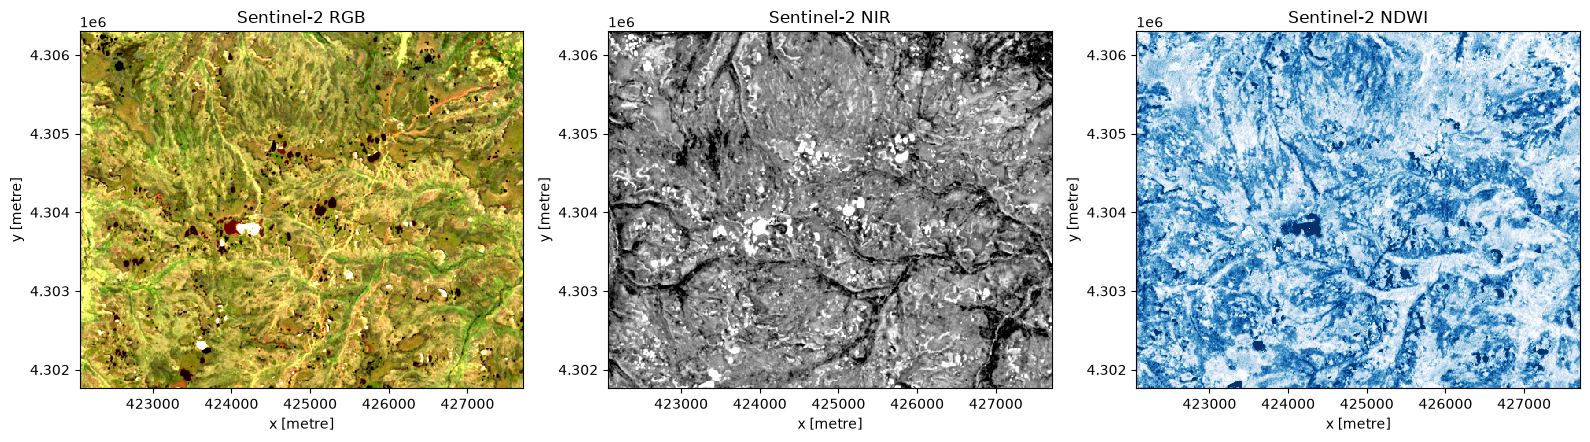

In [34]:
def makeSentinelSubplot(sentinelData, bands, ax, cmap="Greys"):
    if (len(bands) == 1):
        image = sentinelData[bands[0]].isel(time=0)
    else:
        image = sentinelData[bands].isel(time=0).to_array()

    if len(bands) == 1:
        image.plot.imshow(
            robust=True,
            ax=ax,
            cmap=cmap,
            add_colorbar=False
        )
    else:
        image.plot.imshow(
            robust=True,
            ax=ax,
        )

    return ax

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 7))
ax1 = makeSentinelSubplot(sentinelData, ["red", "green", "blue"], ax1)
ax1.set_title("Sentinel-2 RGB")
ax1.set_aspect('equal')

ax2 = makeSentinelSubplot(sentinelData, ["nir"], ax2)
ax2.set_title("Sentinel-2 NIR")
ax2.set_aspect('equal')

ax3 = makeSentinelSubplot(sentinelData, ["ndwi"], ax3, cmap="Blues")
ax3.set_title("Sentinel-2 NDWI")
ax3.set_aspect('equal')

plt.tight_layout()
plt.show()

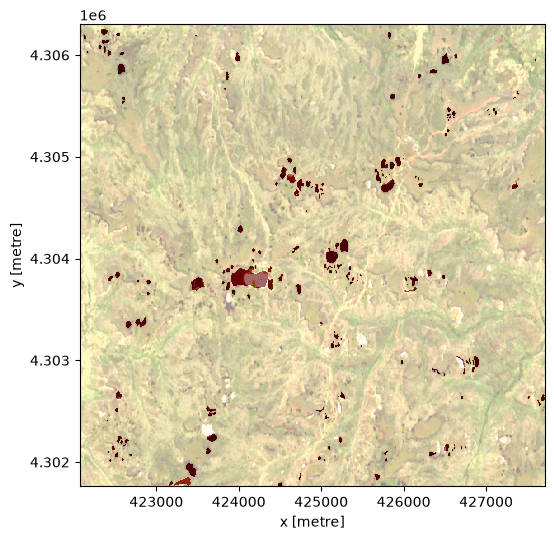

In [45]:
mask = rasterizeOverpass(gdf_projected, sentinelData["red"].isel(time=0))
rgb_image = sentinelData[["red", "green", "blue"]].isel(time=0).to_array()

fig, ax = plt.subplots(figsize=(6, 6))
rgb_image.plot.imshow(ax=ax, robust=True)
ax.set_title("Sentinel 2 RGB With Overpass Water Mask")
mask.plot.imshow(ax=ax, cmap="Reds", alpha=0.6, vmin=0, vmax=1, add_colorbar=False)

plt.show()